# Week 7 Homework: Lists and Tuples

**Name:** ______________________

**Instructions**
- Complete each problem in the code cell below it. Write your pseudocode first, in the `'''` block.
- Replace every `pass` with your own code. Don't change the function names.
- Many problems end with **test lines**. Run the cell: if your code is correct, it prints `✅`. If not, you get an `AssertionError`.
- Before you submit, go to **Kernel → Restart & Run All** and make sure every cell runs without errors.

| Part | Topic                                   | Points |
|------|-----------------------------------------|--------|
| A    | List basics, indexing, slicing           | 20     |
| B    | List methods and processing              | 25     |
| C    | List comprehensions                       | 15     |
| D    | Files and lists                            | 10     |
| E    | 2D lists                                   | 15     |
| F    | Tuples                                     | 5      |
| G    | Plotting with matplotlib                   | 10     |
|      | **Total**                                  | **100** |

---
## Part A: List Basics, Indexing and Slicing (20 pts)

**A1. Coffee Shop Menu (5 pts)**

1. Create a list called `menu` with these items: `"latte"`, `"mocha"`, `"espresso"`, `"cold brew"`, `"chai"`.
2. Print the first item, the last item (use a **negative** index) and the number of items.
3. Change `"mocha"` to `"cappuccino"` and print the updated list.

In [1]:
'''
Create a list of menu items.
Print the first and last items and the list length.
Replace the second item and print the updated list.
'''
menu = ['latte', 'mocha', 'espresso', 'cold brew', 'chai']
print(menu[0], menu[-1], len(menu))
menu[1] = 'cappuccino'
print(menu)

latte chai 5
['latte', 'cappuccino', 'espresso', 'cold brew', 'chai']


**A2. Weekly Sales Slices (5 pts)**

`daily_sales` holds a store's sales for 7 days, Monday through Sunday. Use **slicing** to create:
- `weekdays`: Monday through Friday
- `weekend`: Saturday and Sunday
- `midweek`: Tuesday, Wednesday and Thursday

In [2]:
'''
Slice the first five sales, last two sales, and Tuesday through Thursday.
'''
daily_sales = [210, 185, 240, 198, 305, 410, 375]

weekdays = daily_sales[:5]
weekend = daily_sales[5:]
midweek = daily_sales[1:4]

print(weekdays, weekend, midweek)

# Tests
assert weekdays == [210, 185, 240, 198, 305]
assert weekend == [410, 375]
assert midweek == [185, 240, 198]
print("✅ A2 passed")

[210, 185, 240, 198, 305] [410, 375] [185, 240, 198]
✅ A2 passed


**A3. Stock Check (5 pts)**

Write a function `in_stock(item, inventory)` that returns the string `"<item> is in stock"` if `item` is in the `inventory` list, and `"<item> is out of stock"` otherwise. Use the `in` operator.

In [3]:
'''
Check whether the item is in inventory and return the matching message.
'''
def in_stock(item, inventory):
    return f"{item} is in stock" if item in inventory else f"{item} is out of stock"


inventory = ["laptop", "mouse", "monitor", "keyboard"]
print(in_stock("mouse", inventory))
print(in_stock("webcam", inventory))

# Tests
assert in_stock("mouse", inventory) == "mouse is in stock"
assert in_stock("webcam", inventory) == "webcam is out of stock"
print("✅ A3 passed")

mouse is in stock
webcam is out of stock
✅ A3 passed


**A4. Index Loop (5 pts)**

Use a `for` loop with `range(len(...))` to print each employee with their badge number. The badge number is the **index + 100**.

Expected output:
```
Badge 100: Ana
Badge 101: Ben
Badge 102: Cara
Badge 103: Dev
```

In [4]:
'''
Loop over employee indices and print each badge number and name.
'''
employees = ['Ana', 'Ben', 'Cara', 'Dev']
for i in range(len(employees)):
    print(f'Badge {i + 100}: {employees[i]}')

Badge 100: Ana
Badge 101: Ben
Badge 102: Cara
Badge 103: Dev


---
## Part B: List Methods and Processing (25 pts)

**B1. Order Queue (10 pts)**

Start with `queue = ["Order 1", "Order 2", "Order 3"]` and do these steps **in order**, printing the list after each one:
1. `append` `"Order 4"`.
2. A VIP order arrives: `insert` `"Order VIP"` at the **front**.
3. `"Order 2"` was cancelled: `remove` it.
4. Serve the first order: `pop(0)` it and print `"Now serving: <order>"`.
5. Print how many orders are still waiting.

In [2]:
'''
Append a new order and print the queue.
Insert the VIP order first and print the queue.
Remove the cancelled order and print the queue.
Pop the first order, print the queue and the served order.
Print the remaining number of orders.
'''
queue = ['Order 1', 'Order 2', 'Order 3']
queue.append('Order 4')
print(queue)
queue.insert(0, 'Order VIP')
print(queue)
queue.remove('Order 2')
print(queue)
served = queue.pop(0)
print(queue)
print(f'Now serving: {served}')
print('Orders waiting:', len(queue))

['Order 1', 'Order 2', 'Order 3', 'Order 4']
['Order VIP', 'Order 1', 'Order 2', 'Order 3', 'Order 4']
['Order VIP', 'Order 1', 'Order 3', 'Order 4']
['Order 1', 'Order 3', 'Order 4']
Now serving: Order VIP
Orders waiting: 3


**B2. Sales Summary Function (10 pts)**

Write a function `sales_summary(sales)` that takes a list of daily sales amounts and **returns a tuple** `(total, average, highest, lowest)`. Round the average to 2 decimals.

Calculate `total` with a **loop and an accumulator**, not `sum()`. You may use `max()` and `min()` for the others.

In [6]:
'''
Start total at zero and add each sale in a loop.
Calculate the rounded average, highest and lowest values.
Return all four values as a tuple.
'''
def sales_summary(sales):
    total = 0
    for sale in sales:
        total += sale
    average = round(total / len(sales), 2)
    return (total, average, max(sales), min(sales))


week = [210, 185, 240, 198, 305, 410, 375]
total, average, highest, lowest = sales_summary(week)
print(f"Total: ${total}  Average: ${average}  High: ${highest}  Low: ${lowest}")

# Tests
assert sales_summary(week) == (1923, 274.71, 410, 185)
assert sales_summary([10, 20]) == (30, 15.0, 20, 10)
print("✅ B2 passed")

Total: $1923  Average: $274.71  High: $410  Low: $185
✅ B2 passed


**B3. Safe Copy (5 pts)**

The code below has a bug: changing `sale_prices` also changes `regular_prices`. Fix the line marked `# BUG` so that `regular_prices` stays unchanged. In a comment, explain **why** the original line caused the problem.

In [ ]:
regular_prices = [20.0, 35.0, 50.0]
sale_prices = regular_prices.copy()  # Make a separate list

for i in range(len(sale_prices)):
    sale_prices[i] = sale_prices[i] * 0.75

print("Regular:", regular_prices)
print("Sale:   ", sale_prices)

# Why did the original line cause a problem?
# Both variables originally referenced the same list, so changes affected both.

# Tests
assert regular_prices == [20.0, 35.0, 50.0]
assert sale_prices == [15.0, 26.25, 37.5]
print("✅ B3 passed")

Regular: [20.0, 35.0, 50.0]
Sale:    [15.0, 26.25, 37.5]
✅ B3 passed


---
## Part C: List Comprehensions (15 pts)

Use a **list comprehension** for each part. Each answer should be a single line.

In [8]:
prices = [4.50, 12.00, 8.75, 22.00, 3.25, 15.50]
products = ["notebook", "pen", "backpack", "calculator", "ruler"]

# C1 (5 pts): every price with a $1.00 shipping fee added
with_shipping = [price + 1 for price in prices]

# C2 (5 pts): only the prices over $10
premium = [price for price in prices if price > 10]

# C3 (5 pts): every product name in UPPERCASE, keeping only names longer than 5 characters
long_names = [product.upper() for product in products if len(product) > 5]

print(with_shipping)
print(premium)
print(long_names)

# Tests
assert with_shipping == [5.5, 13.0, 9.75, 23.0, 4.25, 16.5]
assert premium == [12.0, 22.0, 15.5]
assert long_names == ["NOTEBOOK", "BACKPACK", "CALCULATOR"]
print("✅ Part C passed")

[5.5, 13.0, 9.75, 23.0, 4.25, 16.5]
[12.0, 22.0, 15.5]
['NOTEBOOK', 'BACKPACK', 'CALCULATOR']
✅ Part C passed


---
## Part D: Files and Lists (10 pts)

Write two functions:
- `save_list(filename, items)` writes each item in `items` to the file, **one per line**.
- `load_numbers(filename)` reads the file back and **returns a list of floats**. Remember to strip the newline characters.

In [9]:
'''
Open a file for writing and write each item on its own line.
Open the file for reading, convert each stripped line to float, and return the list.
'''
def save_list(filename, items):
    with open(filename, 'w') as file:
        for item in items:
            file.write(str(item) + '\n')


def load_numbers(filename):
    numbers = []
    with open(filename, 'r') as file:
        for line in file:
            numbers.append(float(line.strip()))
    return numbers


expenses = [45.99, 12.5, 230.0, 8.25]
save_list("expenses.txt", expenses)
loaded = load_numbers("expenses.txt")
print(loaded)
print("Total expenses:", sum(loaded))

# Tests
assert loaded == [45.99, 12.5, 230.0, 8.25]
print("✅ Part D passed")

[45.99, 12.5, 230.0, 8.25]
Total expenses: 296.74
✅ Part D passed


---
## Part E: Two-Dimensional Lists (15 pts)

Each row of `regional_sales` is a sales region and each column is a quarter (Q1–Q4).

In [10]:
regions = ["North", "South", "East", "West"]
regional_sales = [
    [120, 135, 150, 160],   # North
    [ 90, 110, 105, 130],   # South
    [200, 180, 210, 225],   # East
    [ 75,  80,  95, 100],   # West
]

**E1 (3 pts):** Print the East region's Q3 sales by indexing `regional_sales`.

**E2 (6 pts):** Write `region_totals(table)` that returns a list with the total for each row. Use **nested loops**, not `sum()`.

**E3 (6 pts):** Write `quarter_totals(table)` that returns a list with the total for each **column** (quarter).

In [11]:
'''
Index the East row and Q3 column.
For each region, loop over its quarters to accumulate its total.
For each quarter, loop over the rows to accumulate its total.
'''
print('East Q3:', regional_sales[2][2])

def region_totals(table):
    totals = []
    for row in table:
        total = 0
        for value in row:
            total += value
        totals.append(total)
    return totals

def quarter_totals(table):
    totals = []
    for col in range(len(table[0])):
        total = 0
        for row in table:
            total += row[col]
        totals.append(total)
    return totals

print(region_totals(regional_sales))
print(quarter_totals(regional_sales))
assert region_totals(regional_sales) == [565, 435, 815, 350]
assert quarter_totals(regional_sales) == [485, 505, 560, 615]
print('✅ Part E passed')

East Q3: 210
[565, 435, 815, 350]
[485, 505, 560, 615]
✅ Part E passed


**E4 (bonus +3 pts):** Use your functions and the `regions` list to print the name of the region with the **highest** total sales.

In [12]:
'''
Find the maximum region total and print the region at its index.
'''
totals = region_totals(regional_sales)
print('Highest sales region:', regions[totals.index(max(totals))])

Highest sales region: East


---
## Part F: Tuples (5 pts)

1. Create a tuple `store_hours` with the values `"8:00 AM"` and `"9:00 PM"`, and print the closing time.
2. Try to change the opening time to `"7:00 AM"`. Catch the error with `try/except` and print a message that explains why it failed.
3. In a comment, give **one** reason a business program might store this data as a tuple instead of a list.

In [13]:
'''
Create a tuple of opening and closing hours.
Print closing time and try to change the opening time.
Catch the TypeError and explain that tuples cannot be modified.
'''
store_hours = ('8:00 AM', '9:00 PM')
print('Closing time:', store_hours[1])
try:
    store_hours[0] = '7:00 AM'
except TypeError:
    print('Cannot change opening time because tuples are immutable.')
# A tuple helps prevent accidental changes to fixed business hours.

Closing time: 9:00 PM
Cannot change opening time because tuples are immutable.


---
## Part G: Plotting with matplotlib (10 pts)

Using the `regions` list and your `region_totals()` result from Part E:

1. **(5 pts)** Make a **bar chart** of total sales by region. Include a title, x-axis label and y-axis label.
2. **(5 pts)** Make a **line chart** of the quarterly totals from `quarter_totals()`. Label the x-axis ticks `Q1`–`Q4`, and add a title and axis labels.

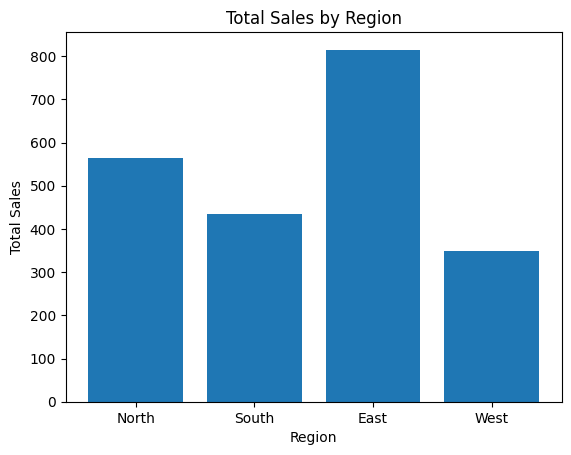

In [14]:
'''
Calculate region totals and display them in a labeled bar chart.
'''
import matplotlib.pyplot as plt
plt.figure()
plt.bar(regions, region_totals(regional_sales))
plt.title('Total Sales by Region')
plt.xlabel('Region')
plt.ylabel('Total Sales')
plt.show()

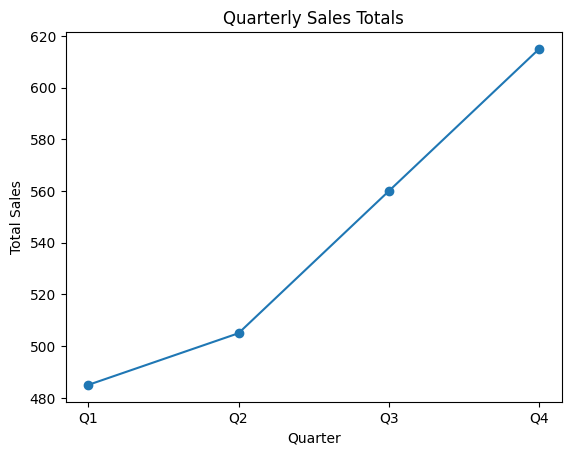

In [15]:
'''
Calculate quarter totals and display a labeled line chart with Q1-Q4 ticks.
'''
quarters = ['Q1', 'Q2', 'Q3', 'Q4']
plt.figure()
plt.plot(quarters, quarter_totals(regional_sales), marker='o')
plt.title('Quarterly Sales Totals')
plt.xlabel('Quarter')
plt.ylabel('Total Sales')
plt.xticks(quarters)
plt.show()